## 1. Setup and Data Generation

First, let's import the necessary libraries and generate mock single-cell data with cell types.


In [1]:
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Add the mock_data module to path
mock_data_path = "/home/converge-bio/virtual-cell/virtual_cell/patient/src/explainability"
if mock_data_path not in sys.path:
    sys.path.append(mock_data_path)

from mock_data import mock_dataset_with_cell_types, get_cell_type_info

# Add B2SC to path and import components
b2sc_path = "/home/converge-bio/B2SC"
if b2sc_path not in sys.path:
    sys.path.append(b2sc_path)

# Import B2SC components directly
from config import B2SCConfig
from pipeline import B2SCPipeline
from data_manager import DataManager
from gmvae_trainer import GMVAETrainer
from bulk_encoder_trainer import BulkEncoderTrainer
from utilities import calculate_pseudobulk

# Set up plotting
plt.style.use('default')
sns.set_palette("husl")

print("✅ All imports successful!")


✅ All imports successful!


### Generate Mock Single-Cell Data

We'll create a realistic single-cell dataset with:
- 100 samples (donors)
- 500 cells per sample
- 2000 genes
- 3 cell types with different proportions


In [2]:
# Parameters for mock data generation
n_samples = 100
n_cells = 500
n_genes = 2000
random_seed = 42

# Define cell type proportions
cell_type_proportions = {
    "T_cell": 0.5,
    "B_cell": 0.3,
    "NK_cell": 0.2
}

# Define differential gene expression patterns for each class
# Class 0: Control samples, Class 1: Disease samples
differential_genes_per_class = [
    {  # Class 0 (Control)
        "T_cell": {10: 0.5, 25: 0.7, 50: 0.6},  # Lower expression
        "B_cell": {100: 0.4, 150: 0.8, 200: 0.5},
        "NK_cell": {300: 0.6, 350: 0.7, 400: 0.4}
    },
    {  # Class 1 (Disease)
        "T_cell": {10: 2.0, 25: 1.8, 50: 2.2},  # Higher expression
        "B_cell": {100: 2.5, 150: 1.5, 200: 2.0},
        "NK_cell": {300: 1.8, 350: 1.6, 400: 2.1}
    }
]

print("Generating mock single-cell data...")
X, y, cell_types = mock_dataset_with_cell_types(
    n_samples=n_samples,
    n_cells=n_cells,
    n_genes=n_genes,
    cell_type_proportions=cell_type_proportions,
    differential_genes_per_class=differential_genes_per_class,
    random_seed=random_seed,
    num_classes=2
)

print(f"Generated data shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Cell types shape: {cell_types.shape}")
print(f"Class distribution: {np.bincount(y)}")


Generating mock single-cell data...
Generated data shape: (100, 500, 2000)
Labels shape: (100,)
Cell types shape: (100, 500)
Class distribution: [50 50]


### Convert to AnnData Format

We'll convert the mock data to AnnData format for compatibility with the B2SC pipeline.


In [3]:
# Reshape data: (n_samples, n_cells, n_genes) -> (n_samples * n_cells, n_genes)
X_reshaped = X.reshape(-1, n_genes)
print(f"Reshaped data: {X_reshaped.shape}")

# Create cell and gene names
cell_names = [f"sample_{i}_cell_{j}" for i in range(n_samples) for j in range(n_cells)]
gene_names = [f"gene_{i}" for i in range(n_genes)]

# Create donor IDs and sample labels for each cell
donor_ids = [f"donor_{i}" for i in range(n_samples) for _ in range(n_cells)]
sample_labels = [y[i] for i in range(n_samples) for _ in range(n_cells)]

# Flatten cell types
cell_types_flat = cell_types.flatten()

# Map cell type indices to names
cell_type_names = list(cell_type_proportions.keys())
cell_type_labels = [cell_type_names[ct] for ct in cell_types_flat]

# Create AnnData object
adata = anndata.AnnData(
    X=X_reshaped,
    obs=pd.DataFrame({
        'donor_id': donor_ids,
        'cell_type': cell_type_labels,
        'sample_label': sample_labels
    }, index=cell_names),
    var=pd.DataFrame(index=gene_names)
)

print(f"AnnData object created: {adata.shape}")
print(f"Observations: {list(adata.obs.columns)}")
print(f"Cell type distribution:")
print(adata.obs['cell_type'].value_counts())


Reshaped data: (50000, 2000)
AnnData object created: (50000, 2000)
Observations: ['donor_id', 'cell_type', 'sample_label']
Cell type distribution:
cell_type
T_cell     24870
B_cell     15009
NK_cell    10121
Name: count, dtype: int64


## 2. Data Splitting

We'll split the data into training (80%), validation (10%), and test (10%) sets at the donor level to ensure no data leakage.


In [4]:
# Get unique donors and their labels
donor_info = adata.obs.groupby('donor_id')['sample_label'].first().reset_index()
unique_donors = donor_info['donor_id'].values
donor_labels = donor_info['sample_label'].values

print(f"Total donors: {len(unique_donors)}")
print(f"Donor label distribution: {np.bincount(donor_labels)}")


Total donors: 100
Donor label distribution: [50 50]


In [5]:
# Split donors into train/val/test (80/10/10)
# First split: 80% train, 20% temp
train_donors, temp_donors, train_labels, temp_labels = train_test_split(
    unique_donors, donor_labels, 
    test_size=0.2, 
    random_state=random_seed, 
    stratify=donor_labels
)

# Second split: 10% val, 10% test from the 20% temp
val_donors, test_donors, val_labels, test_labels = train_test_split(
    temp_donors, temp_labels, 
    test_size=0.5, 
    random_state=random_seed, 
    stratify=temp_labels
)

print(f"\nSplit sizes:")
print(f"Train donors: {len(train_donors)} ({len(train_donors)/len(unique_donors)*100:.1f}%)")
print(f"Val donors: {len(val_donors)} ({len(val_donors)/len(unique_donors)*100:.1f}%)")
print(f"Test donors: {len(test_donors)} ({len(test_donors)/len(unique_donors)*100:.1f}%)")

# Create boolean masks for each split
train_mask = adata.obs['donor_id'].isin(train_donors)
val_mask = adata.obs['donor_id'].isin(val_donors)
test_mask = adata.obs['donor_id'].isin(test_donors)

# Create split datasets
adata_train = adata[train_mask].copy()
adata_val = adata[val_mask].copy()
adata_test = adata[test_mask].copy()

print(f"\nDataset sizes:")
print(f"Train: {adata_train.shape[0]:,} cells from {adata_train.obs['donor_id'].nunique()} donors")
print(f"Val: {adata_val.shape[0]:,} cells from {adata_val.obs['donor_id'].nunique()} donors")
print(f"Test: {adata_test.shape[0]:,} cells from {adata_test.obs['donor_id'].nunique()} donors")



Split sizes:
Train donors: 80 (80.0%)
Val donors: 10 (10.0%)
Test donors: 10 (10.0%)



Dataset sizes:
Train: 40,000 cells from 80 donors
Val: 5,000 cells from 10 donors
Test: 5,000 cells from 10 donors


In [6]:
output_dir = Path("/home/converge-bio/B2SC/examples/tutorial_outputs")

In [7]:
# Save the training data
output_dir.mkdir(parents=True, exist_ok=True)

print("Saving training data...")
adata_train.write_h5ad(output_dir / "train_data.h5ad")
print(f"✅ Training data saved to: {output_dir / 'train_data.h5ad'}")

# Also save validation and test data for completeness
adata_val.write_h5ad(output_dir / "val_data.h5ad")
adata_test.write_h5ad(output_dir / "test_data.h5ad")
print(f"✅ Validation data saved to: {output_dir / 'val_data.h5ad'}")
print(f"✅ Test data saved to: {output_dir / 'test_data.h5ad'}")


Saving training data...
✅ Training data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/train_data.h5ad
✅ Validation data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/val_data.h5ad
✅ Test data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/test_data.h5ad


## 3. GMVAE Training

Now we'll train the Gaussian Mixture Variational Autoencoder (GMVAE) on the single-cell training data.


In [8]:
# Configure B2SC pipeline
config = B2SCConfig(
    sc_training_data_path=str(output_dir / "train_data.h5ad"),
    bulk_data_for_deconv_path=str(output_dir / "pseudobulk_train.h5ad"),
    base_dir=str(output_dir / "results"),
    
    # Model architecture
    gmvae_hidden_dim=1024,  
    bulk_hidden_dim=1024,
    latent_dim=512,
    
    # Training parameters
    gmvae_epochs=3,  # Fewer epochs for tutorial
    bulk_encoder_epochs=30,
    gmvae_lr=1e-3,
    bulk_encoder_lr=1e-5,
    
    # Generation
    num_cells_to_generate=100,
    
    # Device
    device="auto"
)

print(f"Configuration:")
print(f"  Hidden dim: {config.hidden_dim}")
print(f"  Latent dim: {config.latent_dim}")
print(f"  GMVAE epochs: {config.gmvae_epochs}")
print(f"  BulkEncoder epochs: {config.bulk_encoder_epochs}")
print(f"  Device: {config.device}")


Configuration:
  Hidden dim: 1024
  Latent dim: 512
  GMVAE epochs: 3
  BulkEncoder epochs: 30
  Device: auto


In [9]:
# Initialize pipeline
print("Initializing B2SC pipeline...")
pipeline = B2SCPipeline(config)

print(f"✅ Pipeline initialized")
print(f"Data loaded: {pipeline.data_manager.sc_data.shape if pipeline.data_manager.sc_data is not None else 'Not loaded'}")


Initializing B2SC pipeline...
Using 1 GPU(s)
Using 1 GPU(s)
B2SC Pipeline initialized
✅ Pipeline initialized
Data loaded: Not loaded


In [10]:
# Train GMVAE
print("\n" + "="*50)
print("TRAINING GMVAE")
print("="*50)

gmvae_metrics = pipeline.train_gmvae()

print(f"\n✅ GMVAE training completed!")
print(f"Total epochs: {len(gmvae_metrics.history)}")
if gmvae_metrics.history:
    final_metrics = gmvae_metrics.history[-1]
    print(f"Final loss: {final_metrics.total_loss:.4f}")
    print(f"Final reconstruction loss: {final_metrics.reconstruction_loss:.4f}")
    print(f"Final KL loss: {final_metrics.kl_loss:.4f}")


2025-10-28 15:17:47,854 - B2SCPipeline - INFO - Starting GMVAE training...
2025-10-28 15:17:47,855 - B2SCPipeline - INFO - Loading training data...



TRAINING GMVAE
Loading single-cell data...
Normalizing data...
Sum expression per cell: [3486.73727204 3483.50329364 3486.40720111 ... 3480.09418336 3482.1310689
 3479.99457059]
Max sum expression per cell: 3495.861218392317
Cell types:  labels
T_cell     0.496925
B_cell     0.299925
NK_cell    0.203150
Name: proportion, dtype: float64


2025-10-28 15:17:48,846 - B2SCPipeline - INFO - Training data loaded successfully


Loaded 40000 cells with 2000 genes
Found 3 cell types
Batch size: 2000
Initializing GaussianMixtureVAE with input_dim: 2000 hidden_dim: 1024 latent_dim: 512 n_components: 3

GMVAE Summary:
  Total parameters: 7,539,669
  Trainable parameters: 7,539,669
  Non-trainable parameters: 0
  Model size: 28.76 MB
Initialized GMVAE model
Epoch 0 out of 3
************************************* First batch of data: *************************************************
reconstructed.shape: torch.Size([2000, 2000])
data.shape: torch.Size([2000, 2000])
mus.shape: torch.Size([2000, 3, 512])
logvars.shape: torch.Size([2000, 3, 512])
pis.shape: torch.Size([2000, 3])
zs.shape: torch.Size([2000, 512])
Epoch finished
Epoch 1 out of 3
Epoch finished
Epoch 2 out of 3


KeyboardInterrupt: 

## 4. BulkEncoder Training

Now we'll train the BulkEncoder to predict single-cell distribution parameters from bulk data.


2025-10-28 15:13:35,865 - B2SCPipeline - INFO - Starting BulkEncoder training...
/home/converge-bio/B2SC/bulk_encoder_trainer.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental featu


TRAINING BULK ENCODER
Initializing bulkEncoder model...
Initializing bulkEncoder with input_dim: 2000 hidden_dim: 2048 latent_dim: 512 n_components: 3
Initialized BulkEncoder with Xavier weights

BulkEncoder Summary:
  Total parameters: 10,448,899
  Trainable parameters: 10,448,899
  Non-trainable parameters: 0
  Model size: 39.86 MB
BulkEncoder model initialized
Loading scMus, scLogVars, and scPis from /home/converge-bio/B2SC/examples/tutorial_outputs/results
Loaded GMVAE parameters:
  scMus shape: torch.Size([3, 512])
  scLogVars shape: torch.Size([3, 512])
  scPis shape: torch.Size([3])
Training BulkEncoder: Epoch 0 out of 30
Epoch[1/30]: mus_loss:275637.156, vars_loss:255291.875, pis_loss:0.311
Training BulkEncoder: Epoch 1 out of 30
Epoch[2/30]: mus_loss:104975.938, vars_loss:97330.750, pis_loss:0.100
Training BulkEncoder: Epoch 2 out of 30
Epoch[3/30]: mus_loss:54531.820, vars_loss:46884.570, pis_loss:0.100
Training BulkEncoder: Epoch 3 out of 30
Epoch[4/30]: mus_loss:31859.766,

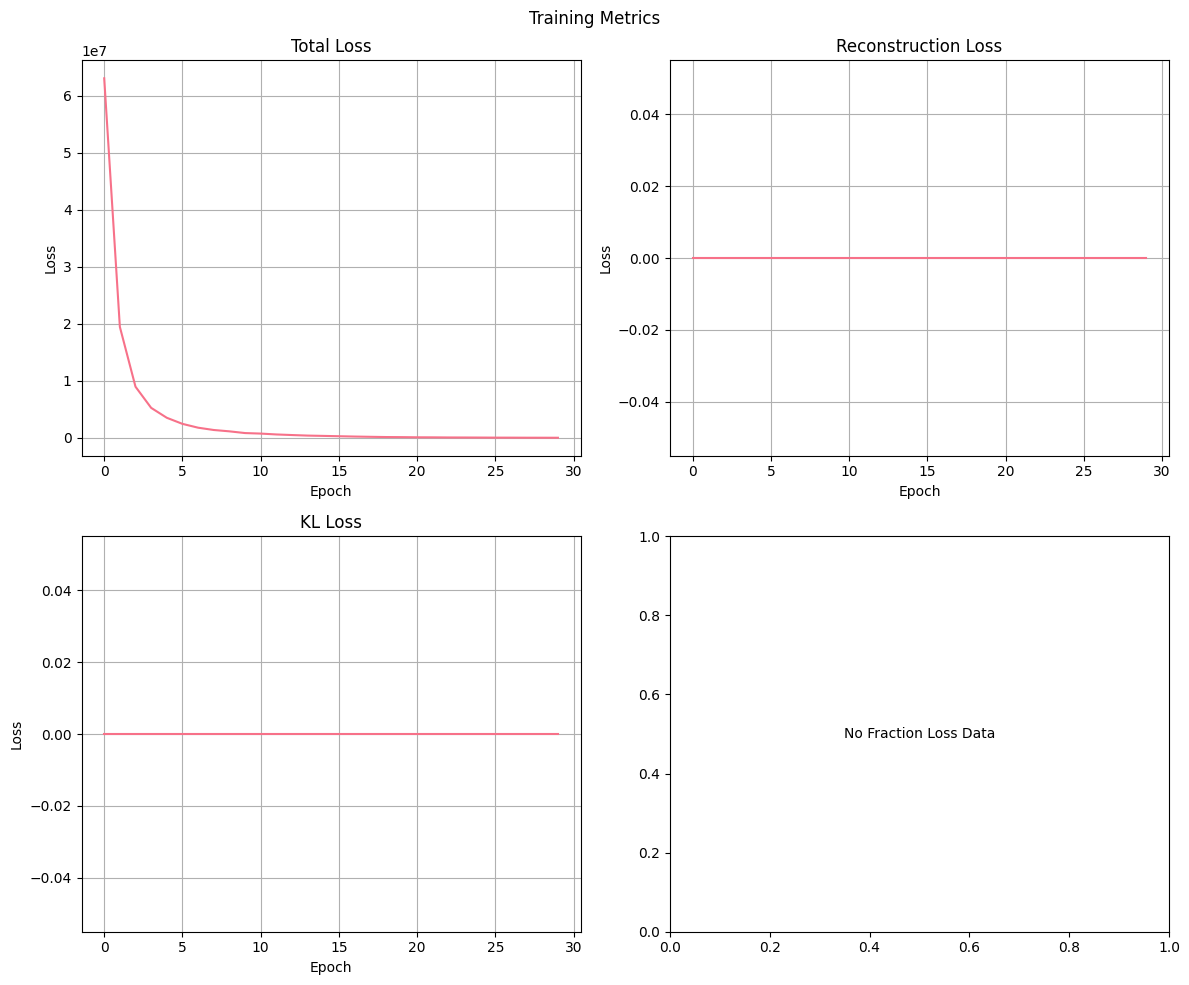

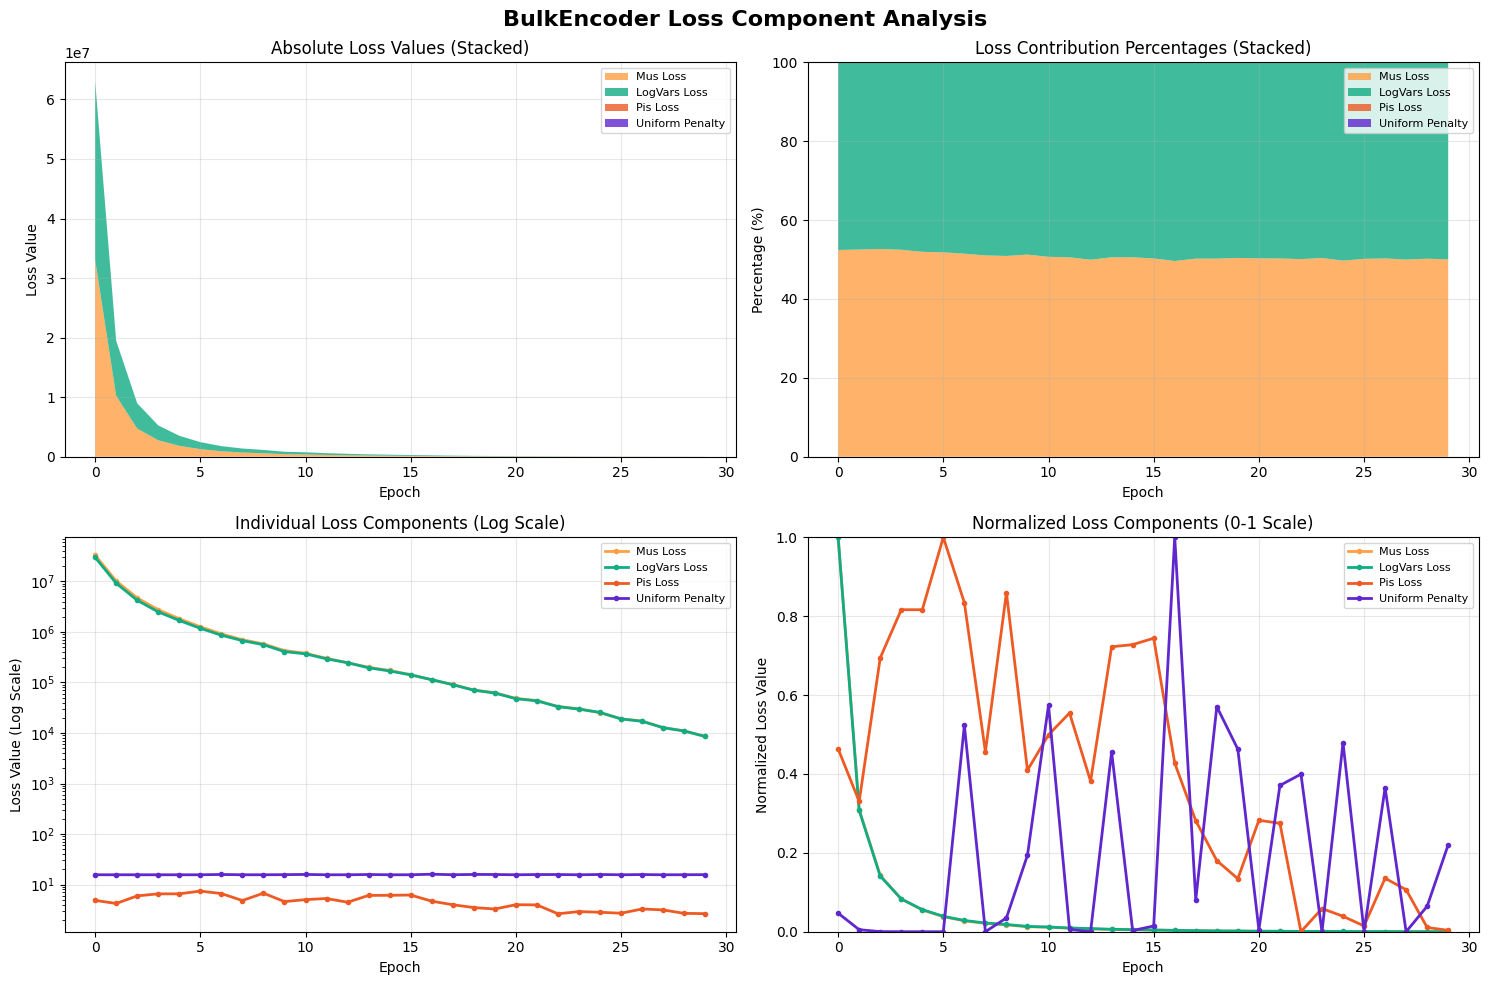

2025-10-28 15:13:42,516 - B2SCPipeline - INFO - BulkEncoder training completed successfully



✅ BulkEncoder training completed!
Total epochs: 30
Final loss: 18789.9757


In [ ]:
# Train BulkEncoder
print("\n" + "="*50)
print("TRAINING BULK ENCODER")
print("="*50)

be_metrics = pipeline.train_bulk_encoder()

print(f"\n✅ BulkEncoder training completed!")
print(f"Total epochs: {len(be_metrics.history)}")
if be_metrics.history:
    final_metrics = be_metrics.history[-1]
    print(f"Final loss: {final_metrics.total_loss:.4f}")


In [ ]:
# Create pseudobulk test data for generation
print("Creating pseudobulk test data...")

from utilities.helpers import calculate_pseudobulk
import scanpy as sc

# Load test data
test_adata = sc.read_h5ad(output_dir / "test_data.h5ad")
print(f"Test data shape: {test_adata.shape}")

# Create pseudobulk by summing over donor_id
pseudobulk_test = calculate_pseudobulk(test_adata, "donor_id")
print(f"Pseudobulk test shape: {pseudobulk_test.shape}")

# Save pseudobulk test data
pseudobulk_test_path = output_dir / "pseudobulk_test.h5ad"
pseudobulk_test.write(pseudobulk_test_path)
print(f"💾 Pseudobulk test data saved to: {pseudobulk_test_path}")

# Show sample info
print(f"📋 Test set donors: {list(pseudobulk_test.obs.index)}")


Creating pseudobulk test data...
Test data shape: (5000, 2000)
Pseudobulk test shape: (10, 2000)
💾 Pseudobulk test data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/pseudobulk_test.h5ad
📋 Test set donors: ['donor_4', 'donor_5', 'donor_31', 'donor_47', 'donor_53', 'donor_55', 'donor_64', 'donor_69', 'donor_84', 'donor_99']


/home/converge-bio/B2SC/utilities/helpers.py:238: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_df = df.groupby(groupby_col).sum()


## 5. Cell Generation

Now that both models are trained, we can generate synthetic single cells from bulk RNA-seq data.
We'll use the test set pseudobulk data for generation.


In [ ]:
# Generate cells from test set pseudobulk data
print("" + "="*50)
print("GENERATING SYNTHETIC CELLS")
print("="*50)

# Use test set pseudobulk for generation
test_bulk_path = str(output_dir / "pseudobulk_test.h5ad")

# Generate cells
generation_results = pipeline.generate_cells(
    bulk_data_path=test_bulk_path,
    num_cells=200  # Generate 200 cells per bulk sample
)

print(f"✅ Cell generation completed!")

2025-10-28 15:01:35,755 - B2SCPipeline - INFO - Starting cell generation...
2025-10-28 15:01:35,764 - B2SCPipeline - INFO - Generating cells for all 10 samples
/home/converge-bio/B2SC/pipeline.py:285: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open 

GENERATING SYNTHETIC CELLS
Loading bulk data from /home/converge-bio/B2SC/examples/tutorial_outputs/pseudobulk_test.h5ad...
Not normalizing sample bulk data
Loaded 10 bulk samples
Initializing GaussianMixtureVAE with input_dim: 2000 hidden_dim: 1024 latent_dim: 512 n_components: 3
Initializing bulkEncoder with input_dim: 2000 hidden_dim: 2048 latent_dim: 512 n_components: 3
Generating 200 cells...
Generating 100th cell...


/home/converge-bio/B2SC/pipeline.py:386: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  generated_aggregate_tensor = torch.load(
/home/converge-bio/B2SC/pipeline.py:389: Futu

Generating 200th cell...
200th generated_aggregate_tensor saved.
Generated cell type proportion:
[0 1 2]
[0.106  0.0565 0.8375]
✅ Cell generation completed!


In [ ]:
# Get summary statistics
summary_stats = generation_results.get_summary_statistics()
print(f"Total cells generated: {summary_stats['total_cells_generated']}")
print(f"Number of bulk samples processed: {summary_stats['num_samples']}")
print(f"Samples: {summary_stats['sample_ids'][:5]}...")  # Show first 5


Total cells generated: 2000
Number of bulk samples processed: 10
Samples: ['donor_4', 'donor_5', 'donor_31', 'donor_47', 'donor_53']...


### Examine Generation Results


In [ ]:
# Print generation summary
print("📊 GENERATION SUMMARY")
print("=" * 30)

# Get detailed summary statistics
summary_stats = generation_results.get_summary_statistics()

print(f"Total samples processed: {summary_stats['num_samples']}")
print(f"Total cells generated: {summary_stats['total_cells_generated']}")
print(f"Sample IDs: {summary_stats['sample_ids']}")

# Show per-sample details
print(f"📋 Per-sample breakdown:")
for sample_id, stats in summary_stats['per_sample_stats'].items():
    print(f"  {sample_id}: {stats['num_cells']} cells, {stats['num_genes']} genes")

# Access the generated data directly
print(f"🧬 Generated data structure:")
print(f"  Data type: Dictionary with {len(generation_results.generated_cells)} samples")
first_sample = list(generation_results.generated_cells.keys())[0]
first_tensor = generation_results.generated_cells[first_sample]
print(f"  Example tensor shape: {first_tensor.shape} (cells × genes)")


### Quality Validation


In [ ]:
# Validate generation quality
print("🔍 QUALITY VALIDATION")
print("=" * 25)

quality_metrics = pipeline.validate_generation_quality(generation_results)

print("📊 Quality Metrics:")
for metric, value in quality_metrics.items():
    if isinstance(value, float):
        print(f"  {metric}: {value:.4f}")
    else:
        print(f"  {metric}: {value}")


### Visualize Generated Cells


In [ ]:
# Convert generation results to AnnData for analysis
generated_adata = generation_results.to_anndata()
print(f"Generated AnnData shape: {generated_adata.shape}")

# Use built-in visualization methods
print("📊 Generating built-in visualizations...")
results_viz_dir = output_dir / "results" / "generation_plots"
generation_results.save_results(results_viz_dir)

print(f"📈 Visualizations saved to: {results_viz_dir}")
print("Generated plots:")
for plot_file in results_viz_dir.glob("*.png"):
    print(f"  - {plot_file.name}")

# Display basic statistics
import numpy as np
total_expression = np.array(generated_adata.X.sum(axis=1)).flatten()
mean_gene_expr = np.array(generated_adata.X.mean(axis=0)).flatten()
sample_counts = generated_adata.obs["sample_id"].value_counts()

print(f"📊 Generated cell statistics:")
print(f"  Total cells: {generated_adata.n_obs}")
print(f"  Total genes: {generated_adata.n_vars}")
print(f"  Mean total expression per cell: {total_expression.mean():.2f} ± {total_expression.std():.2f}")
print(f"  Mean gene expression: {mean_gene_expr.mean():.4f} ± {mean_gene_expr.std():.4f}")
print(f"  Number of highly expressed genes (>1.0): {(mean_gene_expr > 1.0).sum()}")
print(f"  Samples: {list(sample_counts.index)}")
print(f"  Cells per sample: {dict(sample_counts)}")


### Save Generation Results


In [ ]:
# Save generated data
output_file = output_dir / "generated_cells.h5ad"
generated_adata.write(output_file)
print(f"💾 Generated cells saved to: {output_file}")

# Save generation results object
results_file = output_dir / "generation_results.pkl"
generation_results.save(results_file)
print(f"💾 Generation results saved to: {results_file}")

# Print final summary
print(f"🎉 TUTORIAL COMPLETED SUCCESSFULLY!")
print(f"📁 All outputs saved to: {output_dir}")
print(f"📋 Generated files:")
for file_path in output_dir.rglob("*"):
    if file_path.is_file():
        print(f"  - {file_path.name}")


In [ ]:
# Explore the generation results pickle file
import pickle
from pathlib import Path

results_pkl_path = Path("/home/converge-bio/B2SC/examples/tutorial_outputs/generation_results.pkl")

if results_pkl_path.exists():
    print(f"🔍 Loading: {results_pkl_path}")
    
    # Load the pickle file
    with open(results_pkl_path, 'rb') as f:
        loaded_results = pickle.load(f)
    
    print(f"Type: {type(loaded_results)}")
    
    # Show main attributes
    if hasattr(loaded_results, '__dict__'):
        print(f"\nAttributes:")
        for attr_name in sorted(dir(loaded_results)):
            if not attr_name.startswith('_'):
                attr_value = getattr(loaded_results, attr_name)
                if not callable(attr_value):
                    print(f"  {attr_name}: {type(attr_value)}")
else:
    print(f"❌ File not found: {results_pkl_path}")

